In [7]:
from langgraph.graph import StateGraph,START ,END
from typing import TypedDict
from langchain_ollama import ChatOllama

In [8]:
llm = ChatOllama(model='qwen2.5:0.5b-instruct',temperature=0.2,max_token=100)

In [9]:
class BatsmanState(TypedDict):
    runs : int 
    balls : int 
    fours : int 
    sixes : int 

    sr : float # strike rate
    bpb : float # balls per boundary
    boundary_percentage: float
    summary: str
    

In [23]:
def calculate_sr(state:BatsmanState) -> BatsmanState:
    sr = (state['runs']/state['balls']) * 100
    return {'sr':sr}

def calculate_bpb(state:BatsmanState) -> BatsmanState:
    bpb = state['balls'] / (state['fours'] + state['sixes'])
    return {'bpb':bpb}

def calculate_boundary_percentage(state:BatsmanState) -> BatsmanState:
    boundary_percentage = (((state['fours'] * 4) + (state['sixes'] * 6)) / state['runs']) * 100 
    return {'boundary_percentage':boundary_percentage}

def generate_summary(state:BatsmanState) -> BatsmanState:
    query = f'generate a small 2 line summary based on the below data - strike rate = {state['sr']}, balls per boundary = {state['bpb']}, boundary percentage = {state['boundary_percentage']} '
    res = llm.invoke(query)
    return {'summary':res.content}



In [24]:
graph = StateGraph(BatsmanState)

# add nodes 
graph.add_node('calculate_sr',calculate_sr)
graph.add_node('calculate_bpb',calculate_bpb)
graph.add_node('calculate_boundary_percentage',calculate_boundary_percentage)
graph.add_node('generate_summary',generate_summary)

# add edges 
graph.add_edge(START,'calculate_sr')
graph.add_edge(START,'calculate_bpb')
graph.add_edge(START,'calculate_boundary_percentage')

graph.add_edge('calculate_sr','generate_summary')
graph.add_edge('calculate_bpb','generate_summary')
graph.add_edge('calculate_boundary_percentage','generate_summary')

graph.add_edge('generate_summary',END)

# compile graph 
workflow = graph.compile()


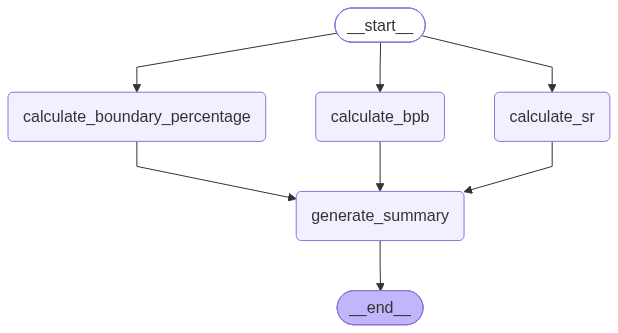

In [25]:
workflow

In [26]:
# execute the graph
inital_state = {
    'runs':100,
    'balls':50,
    'fours':6,
    'sixes':4
}
final_state = workflow.invoke(inital_state)
print(final_state['summary'])

The strike rate is 200%, and there are 5 balls per boundary with a 48% chance of a boundary being hit.


In [17]:
print(final_state['content'])

Certainly! Here's a more detailed outline for your blog post titled "Delhi: A City of History and Culture":

I. Introduction

  * Briefly introduce Delhi as a city with rich history and culture.
  * Explain why it's important to explore this fascinating city.

II. The Beginnings of Delhi

  * Discuss the historical significance of Delhi, including its role in ancient Indian civilization.
  * Provide some interesting facts about the city's early history and architecture.

III. The Mughal Empire: A Brief Overview

  * Explain the Mughal Empire, a period of great power and influence in India during the 17th century.
  * Discuss the impact of the Mughals on Delhi and its surrounding areas.

IV. Modern Delhi: A City of Today

  * Describe the current state of Delhi, including its population, economy, and infrastructure.
  * Highlight some of the most notable landmarks and attractions in the city.

V. Cultural Heritage and Sites

  * Discuss some of the cultural sites and historical monument